In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import html
import unicodedata

# Load datasets
train = pd.read_csv("drive/MyDrive/drugsComTrain_raw.csv", engine="python")
test = pd.read_csv("drive/MyDrive/drugsComTest_raw.csv", engine="python")

df = pd.concat([train, test], ignore_index=True)

df.head()


,uniqueID,drugName,condition,review,rating,date,usefulCount
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combinati...",9,20-May-12,27
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of ...",8,27-Apr-10,192
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5,14-Dec-09,17
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth...",8,03-Nov-15,10
4,35696,Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around...",9,27-Nov-16,37


In [ ]:
# check for missing values
missing_values = df.isnull().any(axis=1)
missing_values_column = df[missing_values]

print(missing_values_column)

        uniqueID                            drugName condition  \
30         51452                        Azithromycin       NaN   
148        61073                                Urea       NaN   
488       132651                             Doxepin       NaN   
733        44297    Ethinyl estradiol / norgestimate       NaN   
851        68697                 Medroxyprogesterone       NaN   
...          ...                                 ...       ...   
213721    170508                          Quetiapine       NaN   
213785    104629  Ethinyl estradiol / levonorgestrel       NaN   
213914    104642  Ethinyl estradiol / levonorgestrel       NaN   
214039       720                 Medroxyprogesterone       NaN   
214726    162326                          Hyaluronan       NaN   

                                                   review  rating       date  \
30         "Very good response. It is so useful for me. "      10  18-Aug-10   
148                               "Accurate inf

In [ ]:
# exact count of missing values in each column
print(df.isnull().sum())

uniqueID          0
drugName          0
condition      1194
review            0
rating            0
date              0
usefulCount       0
dtype: int64


In [ ]:
# filling the missing condition as 'Unknown' because I do not want to lose these rows
df["condition"] = df["condition"].fillna("Unknown")


In [ ]:
# I wanted to clean the HTML entities and other anomalies which are common when data is scraped from the web
def clean_text_healthcare(text):
    if pd.isna(text):
        return text

    # 1. Decode HTML entities (&#039; &amp; etc.)
    text = html.unescape(text)

    # 2. Normalize unicode characters (fix weird symbols)
    text = unicodedata.normalize("NFKC", text)

    # 3. Remove non-breaking spaces and control chars
    text = text.replace("\xa0", " ")
    text = re.sub(r"[\r\n\t]", " ", text)

    # 4. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # 5. Lowercase (safe for NLP models)
    text = text.lower()

    return text


In [ ]:
# applying the above fixed to the column 'review' which contains the anomalies
text_columns = ["review"]

for col in text_columns:
    df[col] = df[col].apply(clean_text_healthcare)


In [ ]:
# Identify numeric conditions (you already did this)
numeric_conditions = df["condition"].astype(str).str.isnumeric()

# Drop them
df = df[~numeric_conditions].reset_index(drop=True)


In [ ]:
assert df["condition"].astype(str).str.isnumeric().sum() == 0


In [ ]:
import re

def clean_condition_strict(text):
    if not isinstance(text, str):
        return None

    text = text.lower()

    # Remove HTML tags completely
    text = re.sub(r"<[^>]+>", "", text)

    # Remove review metadata junk
    text = re.sub(r"\b\d+\s*users found.*", "", text)

    # Remove standalone numbers
    if text.strip().isdigit():
        return None

    # Normalize spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Drop very short leftovers
    if len(text) < 3:
        return None

    return text


In [ ]:
df["condition"] = df["condition"].apply(clean_condition_strict)

# Drop rows where condition was junk
df = df.dropna(subset=["condition"]).reset_index(drop=True)


In [ ]:
# No numeric-only conditions
assert df["condition"].astype(str).str.isnumeric().sum() == 0

# No HTML junk
assert df["condition"].str.contains("users found", regex=False).sum() == 0
assert df["condition"].str.contains("</span>", regex=False).sum() == 0


In [ ]:
# checking if my logics are working or not
sample_idx = 161296

print("BEFORE:\n", df.loc[sample_idx, "review"])
print("\nAFTER:\n", clean_text_healthcare(df.loc[sample_idx, "review"]))


BEFORE:
 "i've been taking adderall for 3 years and have experienced extreme nervousness, loss of appetite, trouble sleeping, dry mouth, dizziness etc. adderall is not for all."

AFTER:
 "i've been taking adderall for 3 years and have experienced extreme nervousness, loss of appetite, trouble sleeping, dry mouth, dizziness etc. adderall is not for all."


In [ ]:
# checking if my logics are working or not

df_raw = pd.read_csv("drive/MyDrive/drugsComTrain_raw.csv", engine="python")

In [ ]:
# checking if my code are working or not

print("RAW:\n", df_raw.loc[161296, "review"])
print("\nCLEANED:\n", clean_text_healthcare(df_raw.loc[161296, "review"]))


RAW:
 "I&#039;ve had chronic constipation all my adult life. Tried Linzess, it worked for a month then stopped. Doctor started me on Amitiza (24 mg) and it is a miracle. I&#039;ve been on for four months now. After a life of 7-10 days between bowel motions, I now go comfortably 3-4 times per week. No pain, very little gas. It&#039;s a miracle for me."

CLEANED:
 "i've had chronic constipation all my adult life. tried linzess, it worked for a month then stopped. doctor started me on amitiza (24 mg) and it is a miracle. i've been on for four months now. after a life of 7-10 days between bowel motions, i now go comfortably 3-4 times per week. no pain, very little gas. it's a miracle for me."


In [ ]:
# now time for some EDA

sns.set(style="whitegrid")

# Avoid scientific notation clutter
pd.set_option("display.float_format", "{:.2f}".format)

# Number of rows and columns
df.shape


(213881, 7)

In [ ]:
# Column names and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 213881 entries, 0 to 213880
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   uniqueID     213881 non-null  int64 
 1   drugName     213881 non-null  object
 2   condition    213881 non-null  object
 3   review       213881 non-null  object
 4   rating       213881 non-null  int64 
 5   date         213881 non-null  object
 6   usefulCount  213881 non-null  int64 
dtypes: int64(3), object(4)
memory usage: 11.4+ MB


In [ ]:
# Quick statistical overview (numerical columns only)
df.describe()


,uniqueID,rating,usefulCount
count,213881.00,213881.00,213881.00
mean,116044.52,6.99,28.09
std,66990.80,3.28,36.40
min,0.00,1.00,0.00
25%,58144.00,5.00,6.00
50%,115860.00,8.00,16.00
75%,173959.00,10.00,36.00
max,232291.00,10.00,1291.00


In [ ]:
# Count reviews per condition
condition_counts = df["condition"].value_counts()

# Display top 10
condition_counts.head(15)




,count
condition,
birth control,38436
depression,12164
pain,8245
anxiety,7812
acne,7435
bipolar disorde,5604
insomnia,4904
weight loss,4857
obesity,4757


In [ ]:
df['condition'] = df['condition'].str.strip().replace(
    'Bipolar Disorde',
    'Bipolar Disorder'
)


In [ ]:
df['condition'].value_counts().head(15)


,count
condition,
birth control,38436
depression,12164
pain,8245
anxiety,7812
acne,7435
bipolar disorde,5604
insomnia,4904
weight loss,4857
obesity,4757


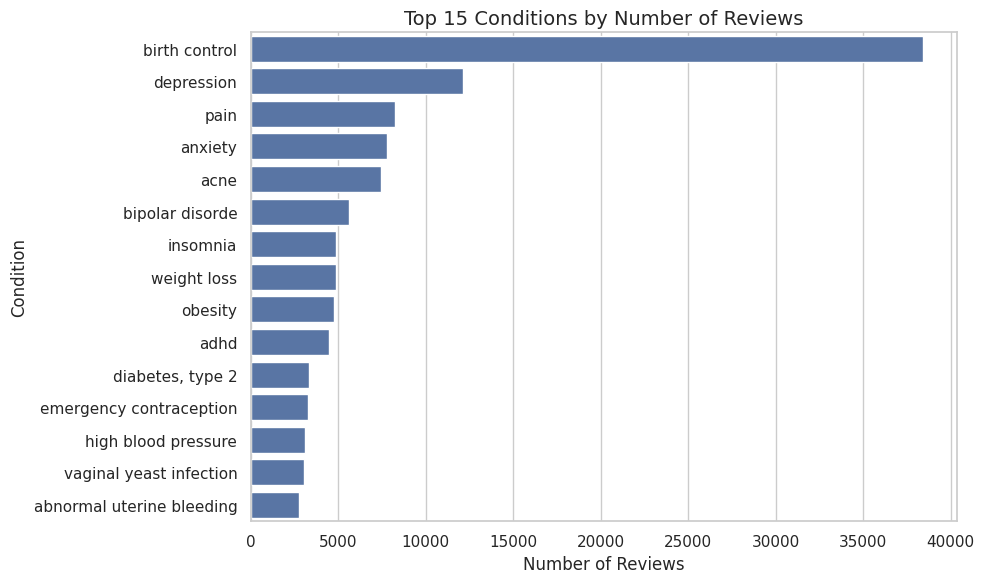

In [ ]:
# Get top 15 conditions
top_conditions = df["condition"].value_counts().head(15)

# Create figure with proper size
plt.figure(figsize=(10, 6))

# Horizontal bar plot
sns.barplot(
    x=top_conditions.values,
    y=top_conditions.index
)

# Add title and axis labels
plt.title("Top 15 Conditions by Number of Reviews", fontsize=14)
plt.xlabel("Number of Reviews", fontsize=12)
plt.ylabel("Condition", fontsize=12)

# Improve layout
plt.tight_layout()

# Show plot
plt.show()


In [ ]:
condition_drug_diversity = (
    df.groupby("condition")["drugName"]
    .nunique()
    .sort_values(ascending=False)
)

condition_drug_diversity.head(15)


,drugName
condition,
unknown,296
not listed / othe,253
pain,219
birth control,181
high blood pressure,146
acne,127
depression,115
rheumatoid arthritis,107
"diabetes, type 2",97


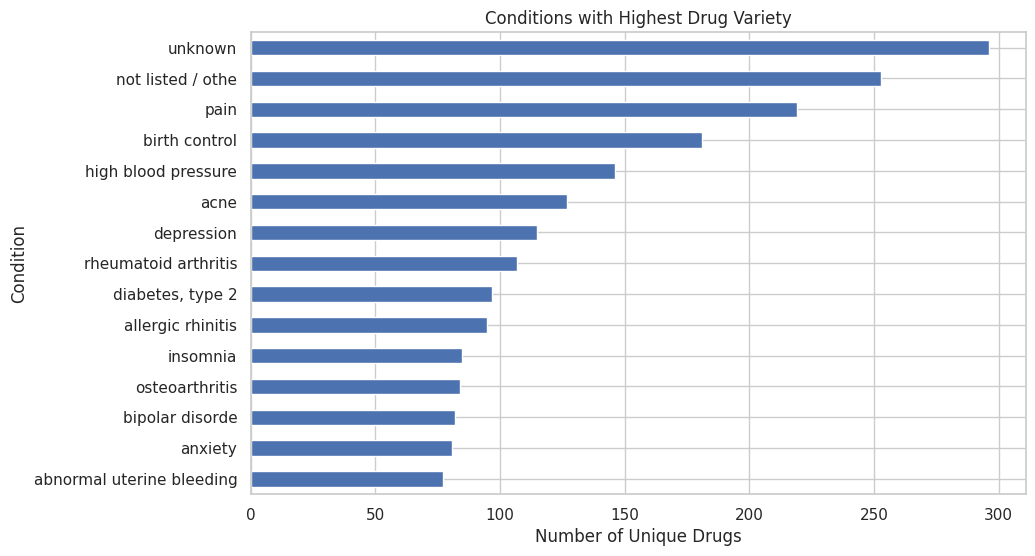

In [ ]:
plt.figure(figsize=(10, 6))
condition_drug_diversity.head(15).plot(kind="barh")
plt.title("Conditions with Highest Drug Variety")
plt.xlabel("Number of Unique Drugs")
plt.ylabel("Condition")
plt.gca().invert_yaxis()
plt.show()


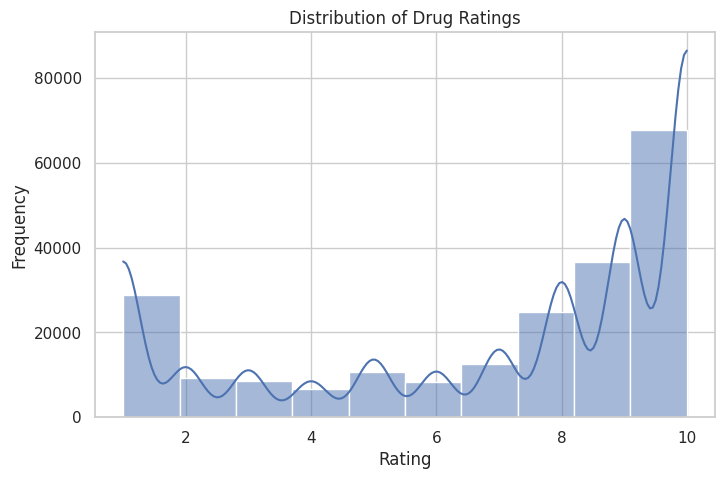

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df["rating"], bins=10, kde=True)
plt.title("Distribution of Drug Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()


In [ ]:
condition_rating_stats = df.groupby("condition").agg(
    mean_rating=("rating", "mean"),
    rating_std=("rating", "std"),
    review_count=("rating", "count")
)

# Focus on statistically meaningful conditions
condition_rating_stats = condition_rating_stats[
    condition_rating_stats["review_count"] > 500
]

condition_rating_stats.head()


,mean_rating,rating_std,review_count
condition,,,
abnormal uterine bleeding,4.38,3.41,2744
acne,7.37,3.04,7435
adhd,7.32,2.94,4509
alcohol dependence,8.83,2.08,518
allergic rhinitis,6.89,3.49,1323


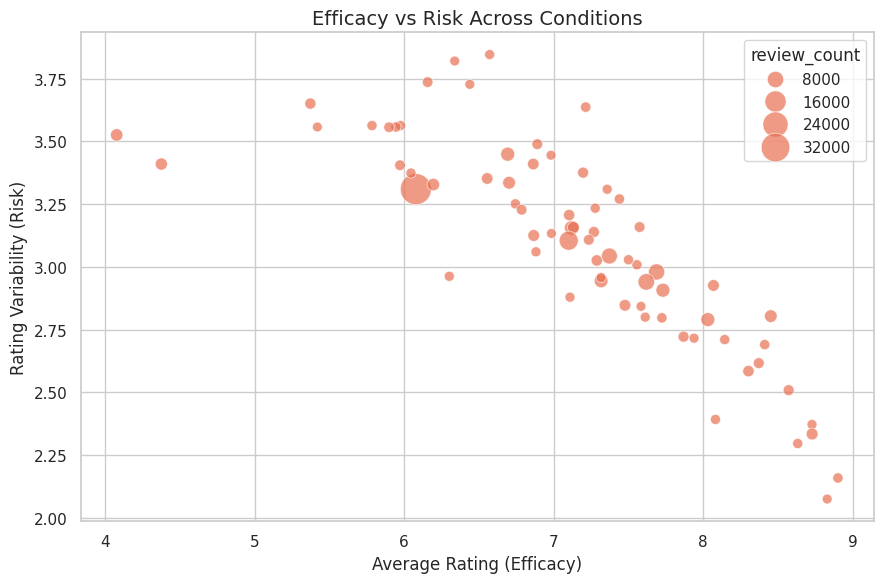

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=condition_rating_stats,
    x="mean_rating",
    y="rating_std",
    size="review_count",
    sizes=(50, 500),
    alpha=0.7,
    color="#e76f51"
)

plt.title("Efficacy vs Risk Across Conditions", fontsize=14)
plt.xlabel("Average Rating (Efficacy)", fontsize=12)
plt.ylabel("Rating Variability (Risk)", fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:
drug_polarization = df.groupby("drugName").agg(
    mean_rating=("rating", "mean"),
    rating_std=("rating", "std"),
    review_count=("rating", "count")
)

# Filter reliable drugs
drug_polarization = drug_polarization[
    drug_polarization["review_count"] > 200
]

drug_polarization.sort_values("rating_std", ascending=False).head(10)


,mean_rating,rating_std,review_count
drugName,,,
Abreva,5.89,3.94,205
Metoclopramide,4.71,3.94,208
Docosanol,5.97,3.93,215
Benzonatate,4.97,3.89,274
Botox,6.44,3.86,209
OnabotulinumtoxinA,6.47,3.85,219
Montelukast,5.89,3.71,245
Levofloxacin,5.30,3.67,424
Cipro,5.66,3.67,213


In [ ]:
# Word count per review
df["review_length"] = df["review"].apply(lambda x: len(x.split()))


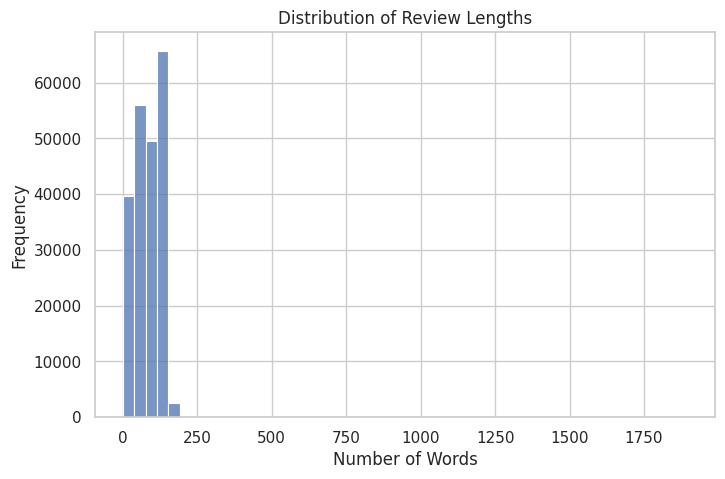

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df["review_length"], bins=50)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()


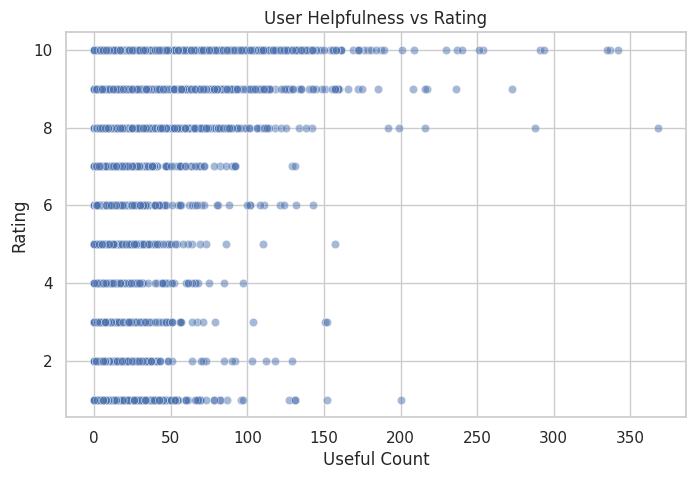

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.sample(5000),
    x="usefulCount",
    y="rating",
    alpha=0.5
)

plt.title("User Helpfulness vs Rating")
plt.xlabel("Useful Count")
plt.ylabel("Rating")
plt.show()


In [ ]:
def detect_iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return (series < lower_bound) | (series > upper_bound)


In [ ]:
condition_rating_stats["outlier_mean_rating"] = detect_iqr_outliers(
    condition_rating_stats["mean_rating"]
)

condition_rating_stats["outlier_rating_std"] = detect_iqr_outliers(
    condition_rating_stats["rating_std"]
)

condition_rating_stats["outlier_review_count"] = detect_iqr_outliers(
    condition_rating_stats["review_count"]
)

condition_rating_stats[
    ["outlier_mean_rating", "outlier_rating_std", "outlier_review_count"]
].sum()


,0
outlier_mean_rating,2
outlier_rating_std,0
outlier_review_count,9


In [ ]:
condition_rating_stats["low_evidence"] = (
    condition_rating_stats["review_count"] < 500
)


In [ ]:
condition_rating_stats["is_actionable_outlier"] = (
    condition_rating_stats["outlier_rating_std"] &
    ~condition_rating_stats["low_evidence"]
)


In [ ]:
import numpy as np

condition_rating_stats["review_bin"] = pd.cut(
    condition_rating_stats["review_count"],
    bins=[0, 10000, 20000, 30000, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)


In [ ]:
condition_rating_stats[["review_count", "review_bin"]].head()


,review_count,review_bin
condition,,
abnormal uterine bleeding,2744,Low
acne,7435,Low
adhd,4509,Low
alcohol dependence,518,Low
allergic rhinitis,1323,Low


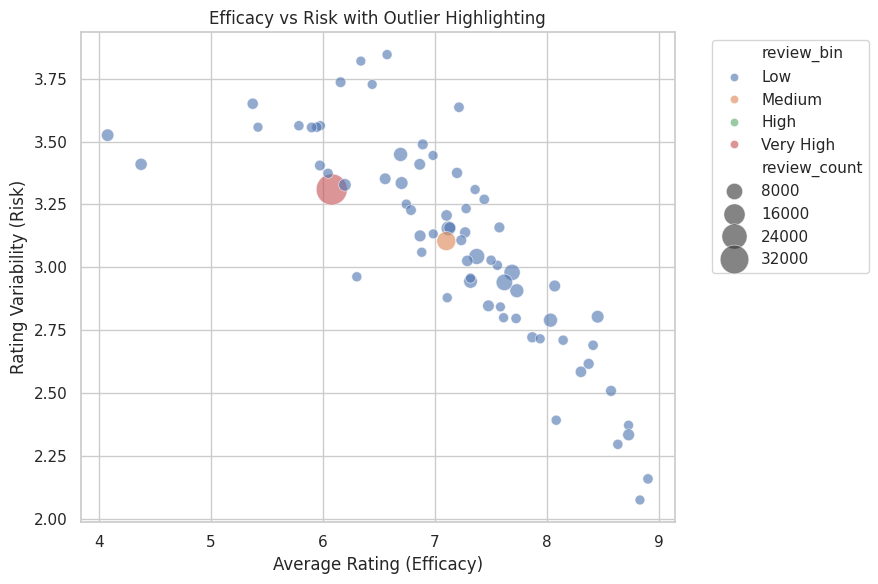

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=condition_rating_stats,
    x="mean_rating",
    y="rating_std",
    size="review_count",
    hue="review_bin",
    sizes=(50, 500),
    alpha=0.6
)

# Overlay actionable outliers
sns.scatterplot(
    data=condition_rating_stats[condition_rating_stats["is_actionable_outlier"]],
    x="mean_rating",
    y="rating_std",
    color="red",
    s=200,
    label="High-Risk Outlier"
)

plt.title("Efficacy vs Risk with Outlier Highlighting")
plt.xlabel("Average Rating (Efficacy)")
plt.ylabel("Rating Variability (Risk)")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [ ]:
def label_efficacy(rating):
    """
    Label drug efficacy using rating as weak supervision.
    """
    if rating >= 8:
        return "positive"
    elif rating <= 4:
        return "negative"
    else:
        return "neutral"


In [ ]:
df["efficacy_label"] = df["rating"].apply(label_efficacy)


In [ ]:
df["efficacy_label"].value_counts()


,count
efficacy_label,
positive,129098
negative,53258
neutral,31525


In [ ]:
risk_keywords = [
    "suicidal", "suicide", "kill myself", "self harm",
    "want to die", "panic attack", "mental breakdown",
    "severe anxiety", "depression worsened"
]


In [ ]:
def detect_risk(text):
    """
    Detect psychological or self-harm risk.
    Returns 1 if risk language is present, else 0.
    """
    return int(any(keyword in text for keyword in risk_keywords))


In [ ]:
df["risk_flag"] = df["review"].apply(detect_risk)


In [ ]:
df["risk_flag"].value_counts(normalize=True)


,proportion
risk_flag,
0,0.96
1,0.04


In [ ]:
side_effect_keywords = [
    "nausea", "vomiting", "weight gain", "weight loss",
    "insomnia", "fatigue", "dizziness", "dry skin",
    "headache", "sexual dysfunction", "diarrhea"
]


In [ ]:
def extract_side_effects(text):
    """
    Extract mentioned side effects from review text.
    """
    return [se for se in side_effect_keywords if se in text]


In [ ]:
df["side_effects"] = df["review"].apply(extract_side_effects)


In [ ]:
def label_side_effect(se_list):
    """
    Label side-effect severity based on number of mentions.
    """
    if len(se_list) == 0:
        return "none"
    elif len(se_list) <= 2:
        return "mild"
    else:
        return "severe"


In [ ]:
df["side_effect_label"] = df["side_effects"].apply(label_side_effect)


In [ ]:
df["side_effect_label"].value_counts()


,count
side_effect_label,
none,161301
mild,49870
severe,2710


In [ ]:
df[
    ["rating", "efficacy_label", "side_effect_label", "risk_flag", "review"]
].sample(5)


,rating,efficacy_label,side_effect_label,risk_flag,review
48795,8,positive,none,0,"""just started topiramate august 2 2013. i've h..."
27170,8,positive,none,0,"""i am in love with this because just had spott..."
76329,9,positive,none,0,"""i got the nexplanon inserted december of 2013..."
92596,8,positive,none,0,"""i have been on ms-contin for 15 years. in tha..."
58170,1,negative,none,0,"""this drug is suppose to the generic for donna..."


In [ ]:
import torch
import pandas as pd
import numpy as np

from transformers import AutoTokenizer, AutoModelForSequenceClassification


In [ ]:
MODEL_NAME = "dmis-lab/biobert-base-cased-v1.1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to("cuda")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were ne

In [ ]:
# Keep only what we need
eff_df = df[["review", "efficacy_label"]].copy()


In [ ]:
# Map string labels to integers (model-friendly)
label_map = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

# Create numeric label column
eff_df["label"] = eff_df["efficacy_label"].map(label_map)


In [ ]:
eff_df["label"].value_counts()


,count
label,
2,129098
0,53258
1,31525


In [ ]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    eff_df[["review", "label"]],
    test_size=0.2,            # 80% train, 20% validation
    stratify=eff_df["label"],
    random_state=42
)


In [ ]:
from datasets import Dataset

# Reset index to avoid HF warnings
train_ds = Dataset.from_pandas(train_df.reset_index(drop=True))
val_ds   = Dataset.from_pandas(val_df.reset_index(drop=True))


In [ ]:
def tokenize_batch(batch):
    """
    Tokenizes review text using BioBERT tokenizer.
    """
    return tokenizer(
        batch["review"],
        padding="max_length",
        truncation=True,
        max_length=256        # Safe length for GPU memory
    )


In [ ]:
train_ds = train_ds.map(tokenize_batch, batched=True)
val_ds   = val_ds.map(tokenize_batch, batched=True)


Map:   0%|          | 0/171104 [00:00<?, ? examples/s]

Map:   0%|          | 0/42777 [00:00<?, ? examples/s]

In [ ]:
train_ds.set_format("torch")
val_ds.set_format("torch")


In [ ]:
train_ds[0]


{'review': '"i’m on the fourth week of vienva and have experienced nausea, headaches, mood swings, spotting and bloating! hopefully these symptoms pass after three months like they say! i hate birth control to begin with because of all the symptoms and i always experience all of them but what are we supposed to do? "',
 'label': tensor(1),
 'input_ids': tensor([  101,   107,   178,   787,   182,  1113,  1103,  2223,  1989,  1104,
           191,  8584,  2497,  1105,  1138,  4531, 22882,   117, 16320,  1116,
           117,  6601, 21583,   117,  3205,  1916,  1105,   171, 23223,  1158,
           106, 16121,  1292,  8006,  2789,  1170,  1210,  1808,  1176,  1152,
          1474,   106,   178,  4819,  3485,  1654,  1106,  3295,  1114,  1272,
          1104,  1155,  1103,  8006,  1105,   178,  1579,  2541,  1155,  1104,
          1172,  1133,  1184,  1132,  1195,  3155,  1106,  1202,   136,   107,
           102,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def compute_metrics(eval_pred):
    """
    Computes accuracy and weighted F1-score.
    """
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="weighted")
    }



In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./biobert_efficacy",
    eval_strategy="epoch",           # ✅ UPDATED
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    fp16=True,                      # GPU optimization
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none",
    logging_steps=100
)


In [ ]:
import torch
import numpy as np
import pandas as pd

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,   # future-proof
    compute_metrics=compute_metrics
)


In [ ]:
# trainer.train()


In [ ]:
# trainer.save_model("./biobert_efficacy_final")
# tokenizer.save_pretrained("./biobert_efficacy_final")


In [ ]:
# model = AutoModelForSequenceClassification.from_pretrained(
#     "./biobert_efficacy_final"
# ).to("cuda")


In [ ]:
import re

In [ ]:
SIDE_EFFECT_NORMALIZATION = {
    # sleep
    "can't sleep": "insomnia",
    "cannot sleep": "insomnia",
    "sleep problems": "insomnia",
    "difficulty sleeping": "insomnia",
    "insomnia": "insomnia",

    # weight
    "gained weight": "weight gain",
    "put on weight": "weight gain",
    "weight gain": "weight gain",

    # dizziness
    "dizzy": "dizziness",
    "dizziness": "dizziness",

    # GI
    "nausea": "nausea",
    "vomiting": "vomiting",
    "diarrhea": "diarrhea",

    # energy
    "tiredness": "fatigue",
    "fatigue": "fatigue",

    # others
    "headache": "headache",
    "dry mouth": "dry mouth",
    "constipation": "constipation",

    # anxiety
    "anxiety attacks": "anxiety",
    "anxiety": "anxiety",
}

In [ ]:
# CANONICAL_SIDE_EFFECTS = {
#     "insomnia",
#     "nausea",
#     "vomiting",
#     "diarrhea",
#     "fatigue",
#     "dizziness",
#     "headache",
#     "weight gain",
#     "weight loss",
#     "dry mouth",
#     "constipation",
#     "anxiety",
#     "depression",
#     "tiredness"
# }
CANONICAL_SIDE_EFFECTS = set(SIDE_EFFECT_NORMALIZATION.values())


In [ ]:
# FRAGMENT_WORDS = {
#     "sleep", "gained", "gain", "feel", "feeling", "weight"
# }


In [ ]:
# import string

# # Normalize negation words too
# NEGATION_WORDS = {
#     "no", "not", "never",
#     "havent", "hasnt", "hadnt",
#     "didnt", "dont", "doesnt",
#     "without", "none", "neither"
# }

# def is_negated(phrase, text, window=5):
#     """
#     Robust negation detection for patient reviews.
#     """

#     # Lowercase
#     text = text.lower()
#     phrase = phrase.lower()

#     # Remove punctuation
#     translator = str.maketrans("", "", string.punctuation)
#     clean_text = text.translate(translator)

#     tokens = clean_text.split()
#     phrase_tokens = phrase.split()
#     phrase_len = len(phrase_tokens)

#     for i in range(len(tokens) - phrase_len + 1):
#         if tokens[i:i + phrase_len] == phrase_tokens:
#             start = max(0, i - window)
#             context = tokens[start:i]

#             if any(neg in context for neg in NEGATION_WORDS):
#                 return True

#     return False


In [ ]:
from transformers import pipeline
ner_pipeline = pipeline(
    task="ner",
    model="d4data/biomedical-ner-all",
    tokenizer="d4data/biomedical-ner-all",
    aggregation_strategy="simple",
    device=0  # use GPU if available, remove if on CPU
)
print(type(ner_pipeline))


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/266M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

<class 'transformers.pipelines.token_classification.TokenClassificationPipeline'>


In [ ]:

# # Phrases that explicitly negate a side effect
# NEGATION_PREFIXES = [
#     "no ",
#     "not ",
#     "never ",
#     "havent ",
#     "hasnt ",
#     "hadnt ",
#     "didnt ",
#     "dont ",
#     "doesnt ",
#     "without "
# ]

# def extract_side_effects(text, condition=None):
#     """
#     Deterministic side-effect extractor with phrase-level negation handling.
#     This version is bulletproof for patient reviews.
#     """

#     # ---------- Normalize text ONCE ----------
#     text_lower = text.lower()
#     translator = str.maketrans("", "", string.punctuation)
#     clean_text = text_lower.translate(translator)

#     condition = condition.lower() if condition else None
#     effects = set()

#     # ---------- Phrase-level extraction ----------
#     for phrase in SIDE_EFFECT_LEXICON:
#         phrase = phrase.lower()

#         # Phrase must appear in text
#         if phrase in clean_text:

#             # Check if THIS phrase is explicitly negated
#             negated = False
#             for neg in NEGATION_PREFIXES:
#                 if f"{neg}{phrase}" in clean_text:
#                     negated = True
#                     break

#             # Only add if NOT negated
#             if not negated:
#                 effects.add(phrase)

#     # ---------- Remove treated condition ----------
#     if condition:
#         effects = {
#             e for e in effects
#             if condition not in e and e not in condition
#         }

#     return list(effects)


# import string

# def extract_side_effects(text, condition=None):
#     """
#     Phrase-based side-effect extractor with explicit negation handling.
#     Deterministic and safe for patient reviews.
#     """

#     # ---------- Normalize text ONCE ----------
#     text_lower = text.lower()
#     translator = str.maketrans("", "", string.punctuation)
#     clean_text = text_lower.translate(translator)

#     condition = condition.lower() if condition else None
#     effects = set()

#     # ---------- Negation prefixes (scoped locally) ----------
#     NEGATION_PREFIXES = [
#         "no ",
#         "not ",
#         "never ",
#         "havent ",
#         "hasnt ",
#         "hadnt ",
#         "didnt ",
#         "dont ",
#         "doesnt ",
#         "without "
#     ]

#     # ---------- Phrase-level extraction ----------
#     for phrase in SIDE_EFFECT_NORMALIZATION.keys():
#         if phrase in clean_text:

#             # Explicit negation check for THIS phrase only
#             if any(f"{neg}{phrase}" in clean_text for neg in NEGATION_PREFIXES):
#                 continue

#             effects.add(phrase)

#     # ---------- Remove treated condition ----------
#     if condition:
#         effects = {
#             e for e in effects
#             if condition not in e and e not in condition
#         }

#     return list(effects)

import string

def extract_side_effects(text, condition=None):
    """
    Phrase-based side-effect extractor with explicit negation handling.
    """

    text_lower = text.lower()
    translator = str.maketrans("", "", string.punctuation)
    clean_text = text_lower.translate(translator)

    condition = condition.lower() if condition else None
    effects = set()

    NEGATION_PREFIXES = [
        "no ",
        "not ",
        "never ",
        "havent ",
        "hasnt ",
        "hadnt ",
        "didnt ",
        "dont ",
        "doesnt ",
        "without "
    ]

    for phrase in SIDE_EFFECT_NORMALIZATION.keys():
        phrase_clean = phrase.translate(translator)

        if phrase_clean in clean_text:
            if any(f"{neg}{phrase_clean}" in clean_text for neg in NEGATION_PREFIXES):
                continue

            effects.add(phrase)

    if condition:
        effects = {
            e for e in effects
            if condition not in e and e not in condition
        }

    return list(effects)



In [ ]:
def clean_side_effects(raw_effects):
    cleaned = set()

    for eff in raw_effects:
        if eff in SIDE_EFFECT_NORMALIZATION:
            norm = SIDE_EFFECT_NORMALIZATION[eff]
            if norm in CANONICAL_SIDE_EFFECTS:
                cleaned.add(norm)

    return sorted(cleaned)


In [ ]:
raw = extract_side_effects(
    "I can't sleep, gained weight, and feel dizzy all the time.",
    condition="Anxiety"
)

print("RAW:", raw)
print("CLEAN:", clean_side_effects(raw))


RAW: ["can't sleep", 'gained weight', 'dizzy']
CLEAN: ['dizziness', 'insomnia', 'weight gain']


In [ ]:
raw = extract_side_effects(
    "This medication worked extremely well for my anxiety with no side effects.",
    condition="Anxiety"
)

print(clean_side_effects(raw))


[]


In [ ]:
raw = extract_side_effects(
    "The drug worked but caused severe nausea.",
    condition="Depression"
)

print(clean_side_effects(raw))


['nausea']


In [ ]:
raw = extract_side_effects(
    "I can't sleep, gained weight, and feel dizzy all the time.",
    condition="Anxiety"
)

print(clean_side_effects(raw))


['dizziness', 'insomnia', 'weight gain']


In [ ]:
raw = extract_side_effects(
    "This drug helped my depression but caused nausea and dry mouth.",
    condition="Depression"
)

print(clean_side_effects(raw))


['dry mouth', 'nausea']


In [ ]:
raw = extract_side_effects(
    "I take this medication for anxiety and it helps a lot.",
    condition="Anxiety"
)

print(clean_side_effects(raw))


[]


In [ ]:
raw = extract_side_effects(
    "After starting this drug I had vomiting and diarrhea.",
    condition="Migraine"
)

print(clean_side_effects(raw))


['diarrhea', 'vomiting']


In [ ]:
raw = extract_side_effects(
    "This medicine makes me feel constant tiredness.",
    condition="Pain"
)

print(clean_side_effects(raw))


['fatigue']


In [ ]:
raw = extract_side_effects(
    "Ugh... dry mouth, headache!!! Can't sleep at night.",
    condition="Allergy"
)

print(clean_side_effects(raw))


['dry mouth', 'headache', 'insomnia']


In [ ]:
raw = extract_side_effects(
    "I feel better now and my condition is under control.",
    condition="Depression"
)

print(clean_side_effects(raw))


[]


In [ ]:
raw = extract_side_effects(
    "Helped my anxiety BUT I can't sleep, gained weight, feel dizzy, and have dry mouth.",
    condition="Anxiety"
)

print(clean_side_effects(raw))


['dizziness', 'dry mouth', 'insomnia', 'weight gain']


In [ ]:
# Start with a small subset for safety
df_subset = df.sample(500, random_state=42).copy()


In [ ]:
def extract_and_clean(row):
    raw = extract_side_effects(
        row["review"],
        condition=row["condition"]
    )
    return clean_side_effects(raw)

df_subset["side_effects"] = df_subset.apply(
    extract_and_clean,
    axis=1
)


In [ ]:
df_subset[["review", "condition", "side_effects"]].head(10)


,review,condition,side_effects
200214,"""knee, loss of cartilage in both knees. series...",osteoarthritis,[]
190508,"""this medication works so well. the depression...",depression,[]
32763,"""i have a bulging disc and low back that has d...",pain,[]
105213,"""this is for my rheumatoid vasculitus. this fi...",rheumatoid arthritis,[]
8839,"""i have been using lyrica for 1 year or so for...",ibromyalgia,[]
159886,"""taking contrave for 3 months. lost 20 pounds....",obesity,[]
1711,"""it works without side effects.""",anxiety,[]
21971,"""same as previous comment. made me sick to my ...","copd, maintenance",[]
101363,"""i've been taking the terbinafine 250mg tab on...",tinea capitis,[]
114593,"""love this medicine. i have lost 24.7 pounds i...",weight loss,[]


In [ ]:
row = df.loc[98666]

raw_effects = extract_side_effects(
    text=row["review"],
    condition=row["condition"]
)

clean_effects = clean_side_effects(raw_effects)

print("REVIEW:")
print(row["review"])
print("\nCONDITION:", row["condition"])
print("\nRAW SIDE EFFECTS:", raw_effects)
print("\nCLEAN SIDE EFFECTS:", clean_effects)


REVIEW:
"i'm a 37 year old male and have been out of the game for a couple of years. now i have met this super hot sexy girl and had issues with anxiety the first time we got intimate. embarrassing and discouraging. so now i got some cialis and we tried again the second time. all i can say is thank you cialis. this stuff really works. the great thing is that i lasted for an hour (never before) giving her ultimate pleasure which in return gave me the greatest joy."

CONDITION: erectile dysfunction

RAW SIDE EFFECTS: ['anxiety']

CLEAN SIDE EFFECTS: ['anxiety']


In [ ]:
df.columns


Index(['uniqueID', 'drugName', 'condition', 'review', 'rating', 'date',
       'usefulCount', 'review_length', 'efficacy_label', 'risk_flag',
       'side_effects', 'side_effect_label'],
      dtype='object')

In [ ]:
# df.to_csv("final_drug_reviews.csv", index=False)


In [ ]:
df_se = df.copy()

# Convert list → one row per side effect
df_se = df_se.explode("side_effects")


In [ ]:
side_effect_counts = (
    df_se
    .dropna(subset=["side_effects"])
    .groupby(["drugName", "side_effects"])
    .size()
    .reset_index(name="number of reviews")
)


In [ ]:
side_effect_counts.head(10)


,drugName,side_effects,number of reviews
0,Abacavir / dolutegravir / lamivudine,diarrhea,2
1,Abacavir / dolutegravir / lamivudine,dizziness,2
2,Abacavir / dolutegravir / lamivudine,fatigue,3
3,Abacavir / dolutegravir / lamivudine,headache,15
4,Abacavir / dolutegravir / lamivudine,insomnia,6
5,Abacavir / dolutegravir / lamivudine,nausea,10
6,Abacavir / dolutegravir / lamivudine,vomiting,2
7,Abacavir / lamivudine,nausea,1
8,Abatacept,fatigue,1
9,Abatacept,headache,1


In [ ]:
drug_review_counts = (
    df.groupby("drugName")
      .size()
      .reset_index(name="total_reviews")
)


In [ ]:
drug_review_counts.head(10)

,drugName,total_reviews
0,A + D Cracked Skin Relief,1
1,A / B Otic,2
2,Abacavir / dolutegravir / lamivudine,70
3,Abacavir / lamivudine,3
4,Abacavir / lamivudine / zidovudine,1
5,Abatacept,25
6,Abilify,591
7,Abilify Discmelt,3
8,Abilify Maintena,5
9,Abiraterone,12


In [ ]:
side_effect_stats = side_effect_counts.merge(
    drug_review_counts,
    on="drugName",
    how="left"
)

# Compute frequency (% of reviews mentioning effect)
side_effect_stats["frequency"] = (
    side_effect_stats["number of reviews"] / side_effect_stats["total_reviews"]
)


In [ ]:
side_effect_stats["frequency"].describe()


,frequency
count,7355.00
mean,0.11
std,0.17
min,0.00
25%,0.02
50%,0.05
75%,0.12
max,1.00


In [ ]:
side_effect_stats[
    side_effect_stats["drugName"] == "Zoloft"
].sort_values("frequency", ascending=False)


,drugName,side_effects,number of reviews,total_reviews,frequency
7269,Zoloft,nausea,74,1077,0.07
7267,Zoloft,headache,67,1077,0.06
7268,Zoloft,insomnia,64,1077,0.06
7272,Zoloft,weight gain,53,1077,0.05
7264,Zoloft,diarrhea,41,1077,0.04
7265,Zoloft,dizziness,22,1077,0.02
7266,Zoloft,fatigue,19,1077,0.02
7273,Zoloft,weight loss,11,1077,0.01
7271,Zoloft,vomiting,9,1077,0.01
7270,Zoloft,sexual dysfunction,7,1077,0.01


In [ ]:
drug_burden = (
    side_effect_stats
    .groupby("drugName")["frequency"]
    .sum()
    .reset_index(name="side_effect_burden")
)


In [ ]:
drug_burden["safety_score"] = 1 / (1 + drug_burden["side_effect_burden"])


In [ ]:
drug_burden["safety_score"].describe()


,safety_score
count,2008.00
mean,0.75
std,0.14
min,0.25
25%,0.67
50%,0.77
75%,0.86
max,1.00


In [ ]:
drug_burden.sort_values("safety_score", ascending=False).head(10)


,drugName,side_effect_burden,safety_score
99,Aluminum chloride hexahydrate,0.00,1.00
1190,Miconazole,0.00,1.00
892,Hypercare,0.00,1.00
1774,Tioconazole,0.01,0.99
888,Hylan g-f 20,0.01,0.99
1221,Monistat 7-Day Combination Pack,0.01,0.99
967,Jublia,0.01,0.99
616,Efinaconazole,0.01,0.99
1220,Monistat 7,0.01,0.99
414,Clobetasol,0.01,0.99


In [ ]:
drug_burden.sort_values("safety_score").head(10)


,drugName,side_effect_burden,safety_score
444,Compro,3.00,0.25
799,Gammagard,3.00,0.25
1434,Phentride,3.00,0.25
759,Flagyl IV,2.50,0.29
1878,Varubi,2.00,0.33
770,FluMist Quadrivalent,2.00,0.33
1431,Phentercot,2.00,0.33
1802,Trelstar LA,2.00,0.33
1890,Vesanoid,2.00,0.33
1718,T-Diet,2.00,0.33


In [ ]:
drug_efficacy = (
    df.groupby("drugName")["rating"]
      .mean()
      .reset_index(name="mean_rating")
)


In [ ]:
drug_efficacy["mean_rating"].describe()


,mean_rating
count,3658.00
mean,7.44
std,2.11
min,1.00
25%,6.29
50%,7.79
75%,9.00
max,10.00


In [ ]:
drug_efficacy["efficacy_score"] = drug_efficacy["mean_rating"] / 10


In [ ]:
drug_scores = (
    drug_efficacy
    .merge(drug_burden[["drugName", "safety_score"]],
           on="drugName",
           how="left")
)


In [ ]:
drug_scores["safety_score"] = drug_scores["safety_score"].fillna(1.0)


In [ ]:
ALPHA = 0.6   # weight for efficacy
BETA  = 0.4   # weight for safety

drug_scores["final_score"] = (
    ALPHA * drug_scores["efficacy_score"] +
    BETA  * drug_scores["safety_score"]
)


In [ ]:
drug_scores.sort_values("final_score", ascending=False).head(10)


,drugName,mean_rating,efficacy_score,safety_score,final_score
13,Absorbine Jr.,10.00,1.00,1.00,1.00
3657,pHisoHex,10.00,1.00,1.00,1.00
0,A + D Cracked Skin Relief,10.00,1.00,1.00,1.00
1,A / B Otic,10.00,1.00,1.00,1.00
3632,Zovia 1 / 50,10.00,1.00,1.00,1.00
33,Acetaminophen / caffeine / magnesium salicylate,10.00,1.00,1.00,1.00
865,Cubicin,10.00,1.00,1.00,1.00
887,Cytra-K,10.00,1.00,1.00,1.00
889,D3,10.00,1.00,1.00,1.00
892,DDAVP Rhinal Tube,10.00,1.00,1.00,1.00


In [ ]:
drug_scores.sort_values(
    ["efficacy_score", "safety_score"],
    ascending=False
).head(1000)


,drugName,mean_rating,efficacy_score,safety_score,final_score
0,A + D Cracked Skin Relief,10.00,1.00,1.00,1.00
1,A / B Otic,10.00,1.00,1.00,1.00
13,Absorbine Jr.,10.00,1.00,1.00,1.00
19,Accolate,10.00,1.00,1.00,1.00
33,Acetaminophen / caffeine / magnesium salicylate,10.00,1.00,1.00,1.00
...,...,...,...,...,...
2949,Sandostatin LAR Depot,9.00,0.90,1.00,0.94
2961,Scullcap,9.00,0.90,1.00,0.94
2980,Senna Plus,9.00,0.90,1.00,0.94
3056,Sorbitol,9.00,0.90,1.00,0.94


In [ ]:
# import re

# def clean_condition(text):
#     if not isinstance(text, str):
#         return None

#     text = text.lower()
#     text = re.sub(r"<.*?>", "", text)      # remove HTML tags
#     text = re.sub(r"users found.*", "", text)
#     text = text.strip()

#     return text if len(text) > 2 else None


In [ ]:
# df["condition"] = df["condition"].apply(clean_text_healthcare)
# df = df.dropna(subset=["condition"])


In [ ]:
df["condition"].value_counts().head(10)


,count
condition,
birth control,38436
depression,12164
pain,8245
anxiety,7812
acne,7435
bipolar disorde,5604
insomnia,4904
weight loss,4857
obesity,4757


In [ ]:
condition_drug_efficacy = (
    df.groupby(["condition", "drugName"])["rating"]
      .mean()
      .reset_index(name="mean_rating")
)

condition_drug_efficacy["efficacy_score"] = (
    condition_drug_efficacy["mean_rating"] / 10
)


In [ ]:
condition_drug_scores = condition_drug_efficacy.merge(
    drug_burden[["drugName", "safety_score"]],
    on="drugName",
    how="left"
)

condition_drug_scores["safety_score"] = (
    condition_drug_scores["safety_score"].fillna(1.0)
)


In [ ]:
ALPHA = 0.6
BETA  = 0.4

condition_drug_scores["final_score"] = (
    ALPHA * condition_drug_scores["efficacy_score"] +
    BETA  * condition_drug_scores["safety_score"]
)


In [ ]:
condition_drug_scores.head()


,condition,drugName,mean_rating,efficacy_score,safety_score,final_score
0,abdominal distension,Bethanechol,9.00,0.90,0.62,0.79
1,abdominal distension,Urecholine,9.00,0.90,0.50,0.74
2,abnormal uterine bleeding,Alesse,4.88,0.49,0.67,0.56
3,abnormal uterine bleeding,Alyacen 1 / 35,1.00,0.10,0.88,0.41
4,abnormal uterine bleeding,Amethia Lo,2.00,0.20,0.67,0.39


In [ ]:
condition_drug_scores["final_score"].describe()


,final_score
count,8879.00
mean,0.78
std,0.16
min,0.19
25%,0.69
50%,0.80
75%,0.90
max,1.00


In [ ]:
# import re

# def normalize_condition(text):
#     if not isinstance(text, str):
#         return None
#     text = text.lower()
#     text = re.sub(r"\(.*?\)", "", text)  # remove parentheses
#     text = text.strip()
#     return text

# df["condition"] = df["condition"].apply(normalize_condition)
# condition_drug_scores["condition"] = condition_drug_scores["condition"].apply(normalize_condition)


In [ ]:
drug_side_effect_map = (
    side_effect_stats
    .groupby("drugName")
    .apply(lambda x: {
        row["side_effects"]: row["frequency"]
        for _, row in x.iterrows()
    })
    .to_dict()
)


/tmp/ipython-input-255/310293005.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: {


In [ ]:
# Total reviews per drug
drug_total_reviews = (
    df.groupby("drugName")
      .size()
      .reset_index(name="total_reviews")
)

# Reviews per (condition, drug)
condition_drug_reviews = (
    df.groupby(["condition", "drugName"])
      .size()
      .reset_index(name="condition_reviews")
)

# Merge + relevance ratio
condition_relevance = condition_drug_reviews.merge(
    drug_total_reviews,
    on="drugName",
    how="left"
)

condition_relevance["relevance_ratio"] = (
    condition_relevance["condition_reviews"] /
    condition_relevance["total_reviews"]
)


In [ ]:
# def recommend_drugs_with_constraints(
#     condition,
#     avoid_side_effects=None,
#     top_n=10,
#     min_reviews=20,
#     max_side_effect_freq=0.05,
#     min_relevance_ratio=0.5,
#     min_condition_reviews=50
# ):
#     """
#     FINAL recommender:
#     - condition-aware
#     - safety-aware
#     - constraint-aware
#     - indication-aware
#     """

#     if avoid_side_effects is None:
#         avoid_side_effects = []

#     condition = normalize_condition(condition)
#     avoid_side_effects = [e.lower() for e in avoid_side_effects]

#     # 1. Condition-specific scores
#     subset = condition_drug_scores[
#         condition_drug_scores["condition"] == condition
#     ].copy()

#     if subset.empty:
#         print(f"No data found for condition: {condition}")
#         return None

#     # 2. Review count filter (evidence)
#     review_counts = (
#         df[df["condition"] == condition]
#         .groupby("drugName")
#         .size()
#         .reset_index(name="review_count")
#     )

#     subset = subset.merge(
#         review_counts,
#         on="drugName",
#         how="left"
#     )

#     subset = subset[subset["review_count"] >= min_reviews]

#     # 3. Condition relevance filter (THIS REMOVES NIACIN)
#     subset = subset.merge(
#         condition_relevance[
#             condition_relevance["condition"] == condition
#         ][["drugName", "relevance_ratio", "condition_reviews"]],
#         on="drugName",
#         how="left"
#     )

#     subset[["relevance_ratio", "condition_reviews"]] = (
#         subset[["relevance_ratio", "condition_reviews"]].fillna(0)
#     )

#     subset = subset[
#         (subset["relevance_ratio"] >= min_relevance_ratio) &
#         (subset["condition_reviews"] >= min_condition_reviews)
#     ]

#     if subset.empty:
#         print("No drugs meet relevance and evidence thresholds.")
#         return None

#     # 4. Side-effect constraint filtering
#     filtered_rows = []

#     for _, row in subset.iterrows():
#         drug = row["drugName"]
#         effects = drug_side_effect_map.get(drug, {})

#         violates = False
#         for effect in avoid_side_effects:
#             if effects.get(effect, 0) >= max_side_effect_freq:
#                 violates = True
#                 break

#         if not violates:
#             filtered_rows.append(row)

#     if not filtered_rows:
#         print("No drugs satisfy the side-effect constraints.")
#         return None

#     # 5. Final ranking
#     result = (
#         pd.DataFrame(filtered_rows)
#         .sort_values("final_score", ascending=False)
#         .head(top_n)
#         .reset_index(drop=True)
#     )

#     return result[[
#         "drugName",
#         "efficacy_score",
#         "safety_score",
#         "final_score",
#         "review_count",
#         "relevance_ratio",
#         "condition_reviews"
#     ]]
def normalize_condition(condition):
    return condition.strip().lower()


def recommend_drugs_with_constraints(
    condition,
    avoid_side_effects=None,
    top_n=10,
    min_reviews=20,
    max_side_effect_freq=0.05,
    min_relevance_ratio=0.5,
    min_condition_reviews=50
):
    """
    FINAL recommender:
    - condition-aware
    - safety-aware
    - constraint-aware
    - indication-aware
    """

    if avoid_side_effects is None:
        avoid_side_effects = []

    condition = normalize_condition(condition)
    avoid_side_effects = [e.lower() for e in avoid_side_effects]

    # 1. Condition-specific scores
    subset = condition_drug_scores[
        condition_drug_scores["condition"] == condition
    ].copy()

    if subset.empty:
        print(f"No data found for condition: {condition}")
        return None

    # 2. Review count filter (evidence)
    review_counts = (
        df[df["condition"] == condition]
        .groupby("drugName")
        .size()
        .reset_index(name="review_count")
    )

    subset = subset.merge(
        review_counts,
        on="drugName",
        how="left"
    )

    subset = subset[subset["review_count"] >= min_reviews]

    # 3. Condition relevance filter (THIS REMOVES NIACIN)
    subset = subset.merge(
        condition_relevance[
            condition_relevance["condition"] == condition
        ][["drugName", "relevance_ratio", "condition_reviews"]],
        on="drugName",
        how="left"
    )

    subset[["relevance_ratio", "condition_reviews"]] = (
        subset[["relevance_ratio", "condition_reviews"]].fillna(0)
    )

    subset = subset[
        (subset["relevance_ratio"] >= min_relevance_ratio) &
        (subset["condition_reviews"] >= min_condition_reviews)
    ]

    if subset.empty:
        print("No drugs meet relevance and evidence thresholds.")
        return None

    # 4. Side-effect constraint filtering
    filtered_rows = []

    for _, row in subset.iterrows():
        drug = row["drugName"]
        effects = drug_side_effect_map.get(drug, {})

        violates = False
        for effect in avoid_side_effects:
            if effects.get(effect, 0) >= max_side_effect_freq:
                violates = True
                break

        if not violates:
            filtered_rows.append(row)

    if not filtered_rows:
        print("No drugs satisfy the side-effect constraints.")
        return None

    # 5. Final ranking
    result = (
        pd.DataFrame(filtered_rows)
        .sort_values("final_score", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

    return result[[
        "drugName",
        "efficacy_score",
        "safety_score",
        "final_score",
        "review_count",
        "relevance_ratio",
        "condition_reviews"
    ]]


In [ ]:
recommend_drugs_with_constraints(
    condition="depression",
    avoid_side_effects=["insomnia"],
    top_n=5
)


,drugName,efficacy_score,safety_score,final_score,review_count,relevance_ratio,condition_reviews
0,L-methylfolate,0.79,0.95,0.85,80,0.88,80
1,St. john's wort,0.87,0.82,0.85,51,0.93,51
2,Deplin,0.75,0.96,0.83,61,0.92,61
3,Effexor,0.58,0.73,0.64,259,0.74,259
4,Trintellix,0.61,0.58,0.59,304,0.63,304


In [ ]:
# Condition must be strings, not numbers
print(condition_drug_scores["condition"].dtype)

# No numeric-only conditions allowed
condition_drug_scores["condition"].str.isnumeric().sum()


object


np.int64(0)

In [ ]:
condition_drug_scores["condition"].drop_duplicates().head(10)


,condition
0,abdominal distension
2,abnormal uterine bleeding
79,abortion
82,acetaminophen overdose
84,acial lipoatrophy
85,acial wrinkles
93,acne
220,actinic keratosis
226,actor ix deficiency
230,acute coronary syndrome


In [ ]:
list(drug_side_effect_map.items())[:3]


[('Abacavir / dolutegravir / lamivudine',
  {'diarrhea': 0.02857142857142857,
   'dizziness': 0.02857142857142857,
   'fatigue': 0.04285714285714286,
   'headache': 0.21428571428571427,
   'insomnia': 0.08571428571428572,
   'nausea': 0.14285714285714285,
   'vomiting': 0.02857142857142857}),
 ('Abacavir / lamivudine', {'nausea': 0.3333333333333333}),
 ('Abatacept',
  {'fatigue': 0.04, 'headache': 0.04, 'nausea': 0.08, 'vomiting': 0.04})]

In [ ]:
def filter_by_side_effects(
    scores_df,
    drug_side_effect_map,
    avoid_effects
):
    """
    Remove drugs that have ANY of the avoided side effects.

    Works whether drug_side_effect_map values are:
    - sets  -> {"insomnia", "nausea"}
    - dicts -> {"insomnia": 0.23, "nausea": 0.14}
    """

    # No constraints → return unchanged
    if not avoid_effects:
        return scores_df

    avoid_set = set(avoid_effects)

    def is_safe(drug):
        effects = drug_side_effect_map.get(drug, set())

        # If effects are stored as dict → use keys
        if isinstance(effects, dict):
            effects = set(effects.keys())

        # If effects are already a set → fine
        return effects.isdisjoint(avoid_set)

    mask = scores_df["drugName"].apply(is_safe)
    return scores_df[mask]


In [ ]:
cond = "depression"

before = condition_drug_scores[
    condition_drug_scores["condition"] == cond
]

after = filter_by_side_effects(
    before,
    drug_side_effect_map,
    avoid_effects=["insomnia"]
)

print("Before:", before.shape[0])
print("After :", after.shape[0])


Before: 115
After : 27


In [ ]:
violations = []

for drug in after["drugName"]:
    if "insomnia" in drug_side_effect_map.get(drug, set()):
        violations.append(drug)

violations


[]

In [ ]:
recommend_drugs_with_constraints(
    condition="depression",
    avoid_side_effects=[],
    top_n=5
)


,drugName,efficacy_score,safety_score,final_score,review_count,relevance_ratio,condition_reviews
0,L-methylfolate,0.79,0.95,0.85,80,0.88,80
1,St. john's wort,0.87,0.82,0.85,51,0.93,51
2,Tranylcypromine,0.85,0.81,0.83,54,0.98,54
3,Deplin,0.75,0.96,0.83,61,0.92,61
4,Wellbutrin XL,0.78,0.79,0.78,184,0.72,184


In [ ]:
recommend_drugs_with_constraints(
    condition="depression",
    avoid_side_effects=["insomnia"],
    top_n=5
)


,drugName,efficacy_score,safety_score,final_score,review_count,relevance_ratio,condition_reviews
0,L-methylfolate,0.79,0.95,0.85,80,0.88,80
1,St. john's wort,0.87,0.82,0.85,51,0.93,51
2,Deplin,0.75,0.96,0.83,61,0.92,61
3,Effexor,0.58,0.73,0.64,259,0.74,259
4,Trintellix,0.61,0.58,0.59,304,0.63,304


In [ ]:
recommend_drugs_with_constraints(
    condition="depression",
    avoid_side_effects=["insomnia", "nausea", "fatigue", "anxiety"],
    top_n=5
)


,drugName,efficacy_score,safety_score,final_score,review_count,relevance_ratio,condition_reviews
0,L-methylfolate,0.79,0.95,0.85,80,0.88,80
1,St. john's wort,0.87,0.82,0.85,51,0.93,51
2,Deplin,0.75,0.96,0.83,61,0.92,61


In [ ]:
print(df["condition"].dtype)


object


In [ ]:
df["condition"].astype(str).str.isnumeric().sum()


np.int64(0)

In [ ]:
df[df["condition"].astype(str).str.isnumeric()]["condition"].unique()


array([], dtype=object)

In [ ]:
assert df["condition"].astype(str).str.isnumeric().sum() == 0


In [ ]:
print(condition_drug_scores["condition"].dtype)


object


In [ ]:
condition_drug_scores["condition"].astype(str).str.isnumeric().sum()


np.int64(0)

In [ ]:
condition_drug_scores[
    condition_drug_scores["condition"].astype(str).str.isnumeric()
]["condition"].unique()


array([], dtype=object)

In [ ]:
assert condition_drug_scores["condition"].astype(str).str.isnumeric().sum() == 0


In [ ]:
condition_drug_scores["condition"].drop_duplicates().head(15)


,condition
0,abdominal distension
2,abnormal uterine bleeding
79,abortion
82,acetaminophen overdose
84,acial lipoatrophy
85,acial wrinkles
93,acne
220,actinic keratosis
226,actor ix deficiency
230,acute coronary syndrome


In [ ]:
df_numeric_conditions = df[
    df["condition"].astype(str).str.isnumeric()
]["condition"].unique()

df_numeric_conditions


array([], dtype=object)

In [ ]:
condition_drug_scores["condition"].unique()[:20]


array(['abdominal distension', 'abnormal uterine bleeding', 'abortion',
       'acetaminophen overdose', 'acial lipoatrophy', 'acial wrinkles',
       'acne', 'actinic keratosis', 'actor ix deficiency',
       'acute coronary syndrome', 'acute lymphoblastic leukemia',
       'acute nonlymphocytic leukemia', 'acute otitis externa',
       'acute promyelocytic leukemia', "addison's disease", 'adhd',
       'adrenocortical insufficiency',
       'adult human growth hormone deficiency', 'aggressive behavi',
       'agitated state'], dtype=object)